# 01 - NMM Brain Simulator Validation

Verify the Jansen-Rit NMM (`app/brain_sim/nmm.py`) produces realistic α-band content and responds plausibly to photic drive.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from app.brain_sim.nmm import JansenRitParams, MultiChannelBrain
from app.brain_sim.photic_input import PhoticInputConfig, StrobeParams, strobe_to_cortical_input

SR = 500

## 1. Default NMM eyes-closed-like baseline

With default Jansen-Rit params we expect a dominant 8-12 Hz α peak (proposal §3.B; Jansen & Rit 1995).

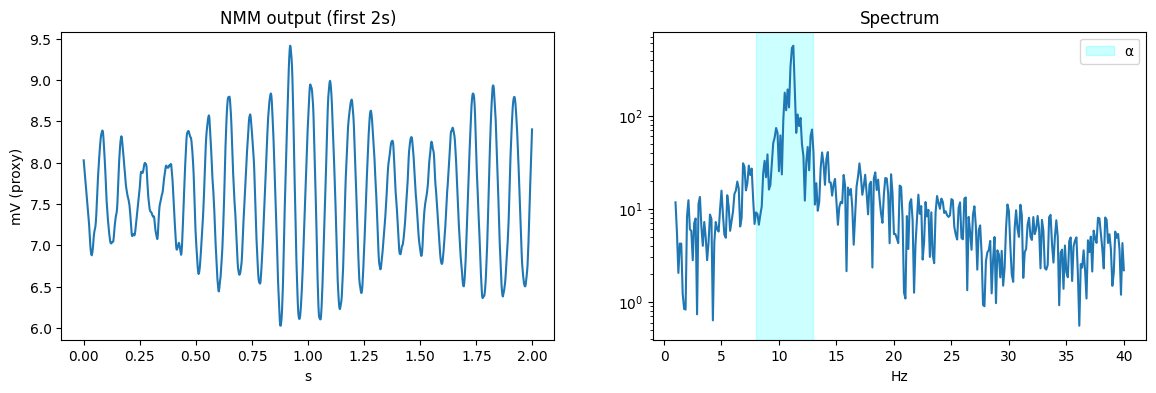

In [2]:
brain = MultiChannelBrain(n_channels=1, alpha_hz=10.0, sampling_rate=SR, seed=42)
brain.run(2.0)  # warm-up
signal = brain.run(8.0)[0]
spectrum = np.abs(np.fft.rfft(signal * np.hanning(len(signal))))
freqs = np.fft.rfftfreq(len(signal), 1.0/SR)
mask = (freqs >= 1) & (freqs <= 40)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,4))
ax1.plot(np.arange(2*SR)/SR, signal[:2*SR]); ax1.set_xlabel('s'); ax1.set_ylabel('mV (proxy)'); ax1.set_title('NMM output (first 2s)')
ax2.semilogy(freqs[mask], spectrum[mask]); ax2.axvspan(8,13,color='cyan',alpha=0.2,label='α'); ax2.set_xlabel('Hz'); ax2.legend(); ax2.set_title('Spectrum')
plt.show()

## 2. Photic driving response

A 6 Hz strobe should enhance 5-7 Hz band power (Spiegler et al. 2011 photic-driving extension).

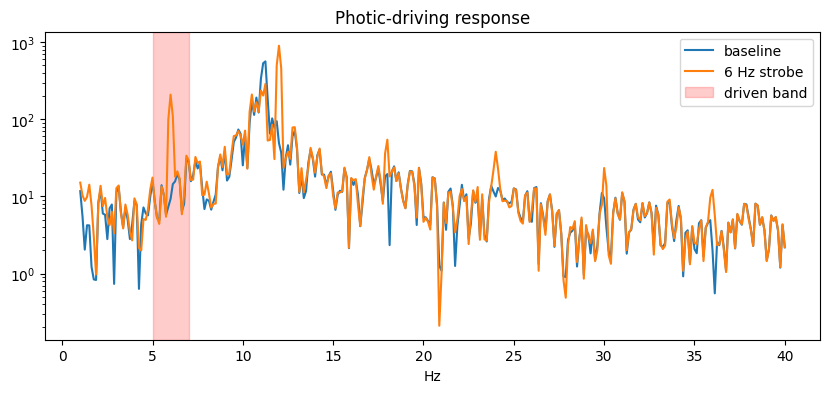

In [3]:
config = PhoticInputConfig(cortical_gain=600.0, base_resonance_hz=6.0, resonance_width_hz=3.0)
strobe = StrobeParams(enabled=True, frequency_hz=6.0, fill=0.3, brightness=0.5)
brain2 = MultiChannelBrain(n_channels=1, alpha_hz=10.0, sampling_rate=SR, seed=42)
brain2.run(2.0)
driven = brain2.run(8.0, photic_fn=lambda t: strobe_to_cortical_input(t, strobe, config))[0]
spec2 = np.abs(np.fft.rfft(driven * np.hanning(len(driven))))
fig, ax = plt.subplots(figsize=(10,4))
ax.semilogy(freqs[mask], spectrum[mask], label='baseline')
ax.semilogy(freqs[mask], spec2[mask], label='6 Hz strobe')
ax.axvspan(5,7,color='red',alpha=0.2,label='driven band'); ax.legend(); ax.set_xlabel('Hz'); ax.set_title('Photic-driving response')
plt.show()

## 3. Domain-randomization preview

Sample 30 simulated subjects and plot the distribution of individual α frequencies & responder types.

Text(0.5, 1.0, 'Sampled α frequencies')

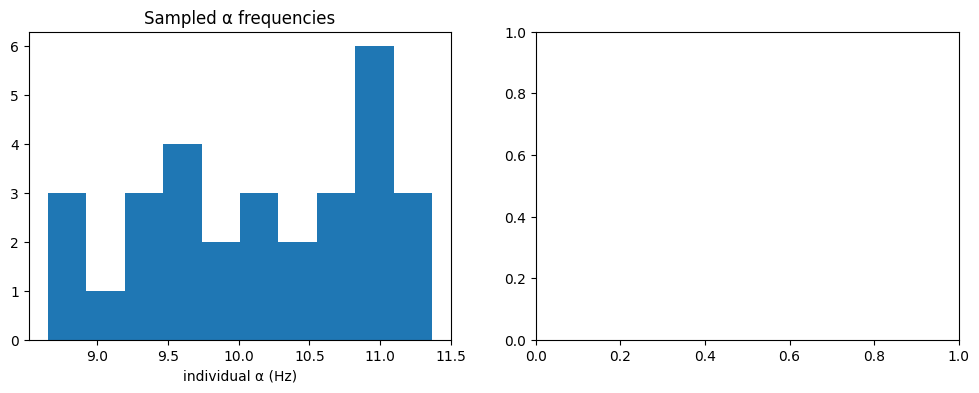

In [4]:
from app.brain_sim.domain_random import RandomizationRanges
ranges = RandomizationRanges()
samples = [ranges.sample(seed=i) for i in range(30)]
alphas = [s.alpha_hz for s in samples]
responders = [s.responder_type for s in samples]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.hist(alphas, bins=10); ax1.set_xlabel('individual α (Hz)'); ax1.set_title('Sampled α frequencies')

In [5]:
from collections import Counter
c = Counter(responders)
ax2.bar(c.keys(), c.values()); ax2.set_title('Responder types')
plt.show()

## 4. Cross-validation against TVB's canonical Jansen-Rit

Our simulator is hand-coded - this section answers the question *"how do we know it's correct?"*. TVB (The Virtual Brain) is the standard NMM library in computational neuroscience and ships Jansen-Rit as a built-in model with the same 6-ODE structure we implement. When both impls are parameterised identically (`v0=6.0` mV per the 1995 paper; TVB ships `v0=5.52` from an alternate variant), they should produce the same natural-mode oscillation.

**Both impls run deterministically here** - we set our `p_std=0` and use TVB's `HeunDeterministic` integrator - so the comparison is between the *natural-mode oscillations* of the two implementations, not between two differently-noise-driven systems. Production use of our impl always has `p_std=22` for realistic stochastic background drive; the noise floor that introduces is orthogonal to whether the equations are correct.

Pass criterion: both peaks in alpha [8, 13] Hz, within 2 Hz of each other, log-PSD correlation across [1, 30] Hz >= 0.7. The same comparison runs as a regression test in `tests/integration/test_tvb_cross_validation.py`.


In [6]:
import warnings
warnings.filterwarnings('ignore')
from scipy.signal import welch
from app.brain_sim.nmm import JansenRitColumn, JansenRitParams

# Both runs are DETERMINISTIC (no stochastic drive) so we measure the
# natural-mode oscillation of the equations, not driven response. Our
# JR's noise term is `bg = p_mean + p_std*randn()`; setting p_std=0
# removes the injected white noise. The model still needs to leave its
# fixed point at y=0 - we perturb y[1] off zero (matching the centre
# of TVB's y1 state_variable_range) so the dynamics roll onto the
# limit cycle just as they do in TVB.
DURATION_S, SETTLE_S, SEED = 12.0, 4.0, 13

# --- Our hand-coded JR, deterministic ---
params = JansenRitParams(p_std=0.0)
col = JansenRitColumn(params, dt=1.0 / SR, seed=SEED)
col.y[1] = 50.0           # kick off the y=0 fixed point
ours = np.zeros(int(DURATION_S * SR))
for i in range(len(ours)):
    ours[i] = col.step(photic_input=0.0)
ours = ours[int(SETTLE_S * SR):]

In [7]:
# --- TVB's JansenRit on a 1-node connectivity ---
from tvb.simulator.lab import integrators, monitors, simulator
from tvb.simulator.coupling import Linear
from tvb.simulator.models.jansen_rit import JansenRit
from tvb.datatypes.connectivity import Connectivity

conn = Connectivity(weights=np.zeros((1,1)), tract_lengths=np.zeros((1,1)),
                     region_labels=np.array(['V1']), centres=np.zeros((1,3)))
conn.configure()
# v0=6.0 matches our JansenRitParams default + the 1995 paper. TVB ships
# v0=5.52 from an alternate variant
model = JansenRit(v0=np.array([6.0]))
integ = integrators.HeunDeterministic(dt=2**-4)
mon = monitors.TemporalAverage(period=2.0)   # 500 Hz output
sim = simulator.Simulator(model=model, connectivity=conn,
    coupling=Linear(a=np.array([0.0])), integrator=integ,
    monitors=(mon,), simulation_length=DURATION_S * 1000.0)
sim.configure()
_, data = sim.run()[0]
tvb = (data[:, 1, 0, 0] - data[:, 2, 0, 0])[int(SETTLE_S * SR):]

2026-05-24 16:07:19,397 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


In [8]:
# --- Welch PSD + headline numbers ---
def psd(trace):
    f, ps = welch(trace, fs=SR, nperseg=min(2048, len(trace)))
    rng = (f >= 1) & (f <= 30)
    return f[rng], ps[rng]

fo, po = psd(ours)
ft, pt = psd(tvb)
peak_ours, peak_tvb = float(fo[np.argmax(po)]), float(ft[np.argmax(pt)])
corr = float(np.corrcoef(np.log10(po + 1e-30), np.log10(pt + 1e-30))[0, 1])

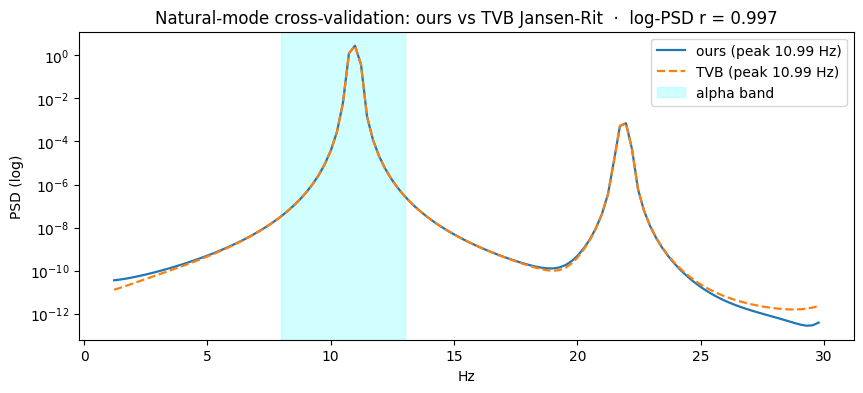

Peak ours: 10.99 Hz  ·  Peak TVB: 10.99 Hz  ·  delta = 0.00
log-PSD correlation [1-30 Hz]: 0.997
VERDICT: PASS  (both in alpha [8,13], delta <= 2 Hz, r >= 0.7)


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(fo, po, label=f'ours (peak {peak_ours:.2f} Hz)', lw=1.6)
ax.semilogy(ft, pt, label=f'TVB (peak {peak_tvb:.2f} Hz)', lw=1.6, linestyle='--')
ax.axvspan(8, 13, color='cyan', alpha=0.18, label='alpha band')
ax.set_xlabel('Hz'); ax.set_ylabel('PSD (log)')
ax.set_title(f'Natural-mode cross-validation: ours vs TVB Jansen-Rit  ·  log-PSD r = {corr:.3f}')
ax.legend(); plt.show()

peak_diff = abs(peak_ours - peak_tvb)
ok = (8 <= peak_ours <= 13 and 8 <= peak_tvb <= 13
      and peak_diff <= 2.0 and corr >= 0.7)
print(f'Peak ours: {peak_ours:.2f} Hz  ·  Peak TVB: {peak_tvb:.2f} Hz  ·  delta = {peak_diff:.2f}')
print(f'log-PSD correlation [1-30 Hz]: {corr:.3f}')
verdict = 'PASS' if ok else 'FAIL'
print(f'VERDICT: {verdict}  (both in alpha [8,13], delta <= 2 Hz, r >= 0.7)')
